# Notebook 04 — Fine-Tuning and Evaluation

Trains a small language model to rank multi-cloud security findings, then measures whether
fine-tuning actually helped.

**Runtime: T4 or L4. Do not use A100 — it is 4× the cost for no benefit here.**

| | |
|---|---|
| Expected total time | 45–70 min on T4, 30–45 min on L4 |
| Expected compute cost | 2–4 units |
| Peak GPU memory | ~9 GB |
| Outputs | trained adapter, 8 figures, 6 CSV tables, manifest |

Every long-running cell shows a live progress bar with a time estimate. The runtime
disconnects automatically when the notebook finishes or hits an error, so no compute is
consumed by an idle session.


## 1 · Install


In [22]:
%pip install -q --upgrade --no-cache-dir \
    "transformers==4.49.0" "accelerate==1.3.0" "peft==0.14.0" \
    "bitsandbytes>=0.45.2" "datasets>=2.19" "scipy>=1.11,<2" \
    "pandas>=2,<3" "matplotlib>=3.8" "seaborn>=0.13" "sentencepiece>=0.2" "tqdm"
print("done")

done


## 2 · Safety controls

Sets up automatic runtime shutdown. `AUTO_DISCONNECT` kills the session when the notebook
finishes or when a cell raises, so a forgotten tab cannot drain compute units.


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import collections, gc, hashlib, json, math, os, platform, random, re, shutil, sys, time, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, transformers, peft, bitsandbytes
from tqdm.auto import tqdm

SEED = 42
AUTO_DISCONNECT = True     # set False to keep the runtime alive after finishing

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

def kill_runtime(reason=""):
    if not AUTO_DISCONNECT:
        print(f"AUTO_DISCONNECT off — runtime kept alive. {reason}"); return
    print(f"\nDisconnecting runtime to stop compute usage. {reason}")
    time.sleep(3)
    try:
        from google.colab import runtime; runtime.unassign()
    except Exception:
        os.kill(os.getpid(), 9)

def guard(fn, *a, **kw):
    """Run fn; on error, print the traceback then release the GPU."""
    try:
        return fn(*a, **kw)
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"\nFAILED: {type(e).__name__}: {e}")
        kill_runtime("Cell failed.")
        raise

print("safety controls active | AUTO_DISCONNECT =", AUTO_DISCONNECT)

safety controls active | AUTO_DISCONNECT = True


## 3 · Check the GPU

Stops immediately if an A100 is attached, since it costs roughly 4× a T4 and this workload
does not need it.


In [ ]:
assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > T4 GPU."

GPU_NAME = torch.cuda.get_device_name(0)
GPU_VRAM = torch.cuda.get_device_properties(0).total_memory / 1024**3
BF16     = torch.cuda.is_bf16_supported()
DTYPE    = torch.bfloat16 if BF16 else torch.float16

print(f"GPU   : {GPU_NAME} ({GPU_VRAM:.1f} GiB)")
print(f"dtype : {DTYPE}")

if "A100" in GPU_NAME or "H100" in GPU_NAME:
    print("\n" + "!"*66)
    print("A100/H100 detected — roughly 4x the cost of a T4 for this workload.")
    print("Switch to T4: Runtime > Change runtime type > T4 GPU.")
    print("To proceed anyway, set ALLOW_EXPENSIVE_GPU = True below and re-run.")
    print("!"*66)
    ALLOW_EXPENSIVE_GPU = False
    assert ALLOW_EXPENSIVE_GPU, "Expensive GPU blocked."

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct" if GPU_VRAM < 22 else "Qwen/Qwen2.5-7B-Instruct"
print(f"\nmodel : {MODEL_ID}")

GPU   : Tesla T4 (14.6 GiB)
dtype : torch.bfloat16

model : Qwen/Qwen2.5-3B-Instruct


## 4 · Load data and mount Drive

Drive holds copies of every artefact as it is produced, so nothing is lost if the session ends.


In [ ]:
from google.colab import files

INPUT_ZIP = Path("/content/mcasm_train_ready.zip")
if not INPUT_ZIP.exists():
    print("Upload mcasm_train_ready.zip")
    files.upload()

BASE = Path("/content/mcasm_project")
DATA, RUN = BASE/"train_ready", BASE/"stage4"
FIG, TAB, CKPT = RUN/"figures", RUN/"tables", RUN/"checkpoints"
for d in (DATA, RUN, FIG, TAB, CKPT): d.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(INPUT_ZIP) as z: z.extractall(DATA)
INPUT_SHA = hashlib.sha256(INPUT_ZIP.read_bytes()).hexdigest()

DRIVE = None
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/mcasm_stage4"); DRIVE.mkdir(parents=True, exist_ok=True)
    print("Drive mirror:", DRIVE)
except Exception as e:
    print(f"Drive unavailable ({type(e).__name__}) — continuing without mirror")

def mirror(src, name):
    if DRIVE is None: return
    try:
        src = Path(src); dst = DRIVE/name
        if src.is_dir(): shutil.copytree(src, dst, dirs_exist_ok=True)
        else: dst.parent.mkdir(parents=True, exist_ok=True); shutil.copy(src, dst)
    except Exception as e:
        print(f"  mirror failed ({name}): {type(e).__name__}")

def read_jsonl(p): return [json.loads(l) for l in open(p, encoding="utf-8") if l.strip()]
splits = {s: read_jsonl(DATA/f"{s}.jsonl") for s in ("train","validation","test")}
manifest_03 = json.loads((DATA/"manifest_03.json").read_text())
MAX_SEQ = int(manifest_03["max_seq_length"])

print(f"\ntrain {len(splits['train'])} | validation {len(splits['validation'])} | test {len(splits['test'])}")
print(f"max_seq_length {MAX_SEQ}")

Upload mcasm_train_ready.zip


Saving mcasm_train_ready.zip to mcasm_train_ready.zip
Mounted at /content/drive
Drive mirror: /content/drive/MyDrive/mcasm_stage4

train 1200 | validation 150 | test 150
max_seq_length 2048


## 5 · Data integrity check

Confirms no cloud resource appears in more than one split. If a resource leaked between
train and test, every result afterwards would be inflated. This asserts, so it stops the
notebook rather than letting a bad run continue.


In [ ]:
rows, res, sizes, ssvc = [], {}, {}, {}
for sp, data in splits.items():
    res[sp]   = {f for r in data for f in r["input_order"]}
    sizes[sp] = [len(r["input_order"]) for r in data]
    sc = collections.Counter()
    for r in data: sc.update(json.loads(r["messages"][2]["content"])["ssvc"].values())
    ssvc[sp] = sc
    rows.append({"split": sp, "instances": len(data), "resources": len(res[sp]),
                 "mean_set_size": round(float(np.mean(sizes[sp])),1)})

integrity = pd.DataFrame(rows)
overlap = {"train~val": len(res["train"] & res["validation"]),
           "train~test": len(res["train"] & res["test"]),
           "val~test":  len(res["validation"] & res["test"])}
display(integrity)
print("cross-split resource overlap:", overlap)
assert sum(overlap.values()) == 0, "RESOURCE LEAKAGE — stop"
print("No leakage.")
integrity.to_csv(TAB/"integrity.csv", index=False); mirror(TAB/"integrity.csv","tables/integrity.csv")

,split,instances,resources,mean_set_size
0,train,1200,257,12.0
1,validation,150,38,12.1
2,test,150,45,11.7


cross-split resource overlap: {'train~val': 0, 'train~test': 0, 'val~test': 0}
No leakage.


### Figure 1 — corpus composition


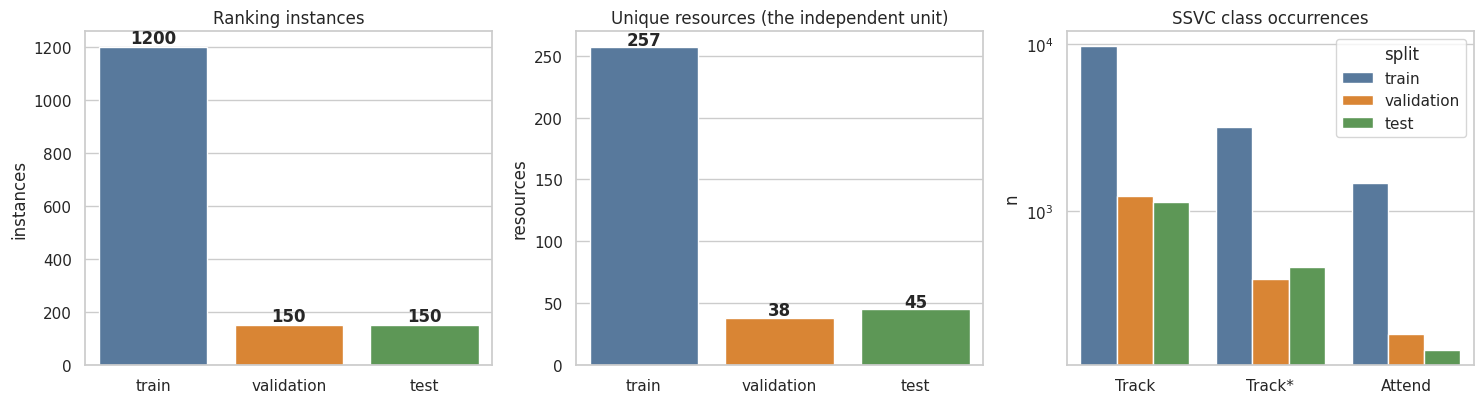

In [ ]:
sns.set_theme(style="whitegrid")
PAL = {"train":"#4C78A8","validation":"#F58518","test":"#54A24B"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

sns.barplot(data=integrity, x="split", y="instances", hue="split", palette=PAL, legend=False, ax=ax[0])
for i,v in enumerate(integrity["instances"]): ax[0].text(i, v+15, str(v), ha="center", fontweight="bold")
ax[0].set_title("Ranking instances"); ax[0].set_xlabel("")

sns.barplot(data=integrity, x="split", y="resources", hue="split", palette=PAL, legend=False, ax=ax[1])
for i,v in enumerate(integrity["resources"]): ax[1].text(i, v+2, str(v), ha="center", fontweight="bold")
ax[1].set_title("Unique resources (the independent unit)"); ax[1].set_xlabel("")

sd = pd.DataFrame([{"split":s,"ssvc":k,"n":v} for s,c in ssvc.items() for k,v in c.items()])
order = [o for o in ["Track","Track*","Attend","Act"] if o in set(sd["ssvc"])]
sns.barplot(data=sd, x="ssvc", y="n", hue="split", palette=PAL, order=order, ax=ax[2])
ax[2].set_yscale("log"); ax[2].set_title("SSVC class occurrences"); ax[2].set_xlabel("")

plt.tight_layout(); plt.savefig(FIG/"fig1_corpus.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig1_corpus.png","figures/fig1_corpus.png")

## 6 · Tokenise

Loss is computed only on the assistant response — prompt tokens are masked out. This also
measures the true length of the target, which sets the generation cap later.


In [ ]:
from transformers import AutoTokenizer
from torch.utils.data import Dataset

tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token_id is None: tok.pad_token = tok.eos_token
tok.padding_side = "right"

def build(rec):
    p = tok.apply_chat_template(rec["messages"][:2], tokenize=False, add_generation_prompt=True)
    a = rec["messages"][2]["content"] + tok.eos_token
    pi = tok(p, add_special_tokens=False)["input_ids"]
    ai = tok(a, add_special_tokens=False)["input_ids"]
    return {"input_ids": (pi+ai)[:MAX_SEQ], "labels": ([-100]*len(pi)+ai)[:MAX_SEQ],
            "n_prompt": len(pi), "n_answer": len(ai)}

class DS(Dataset):
    def __init__(self, recs): self.ex=[build(r) for r in tqdm(recs, desc="tokenising")]
    def __len__(self): return len(self.ex)
    def __getitem__(self,i): return {k:self.ex[i][k] for k in ("input_ids","labels")}

def collate(b):
    mx = max(len(x["input_ids"]) for x in b); pad = tok.pad_token_id
    return {"input_ids": torch.tensor([x["input_ids"]+[pad]*(mx-len(x["input_ids"])) for x in b]),
            "labels":    torch.tensor([x["labels"]+[-100]*(mx-len(x["labels"])) for x in b]),
            "attention_mask": torch.tensor([[1]*len(x["input_ids"])+[0]*(mx-len(x["input_ids"])) for x in b])}

train_ds, val_ds = DS(splits["train"]), DS(splits["validation"])
aud = pd.DataFrame([{"prompt":e["n_prompt"],"answer":e["n_answer"],
                     "total":e["n_prompt"]+e["n_answer"]} for e in train_ds.ex])

# Generation cap measured from data, not guessed. The previous run used 700,
# which is ~1.8x more than needed and made every generation that much slower.
GEN_CAP = int(np.percentile(aud["answer"], 99) * 1.15)
print(f"\ntokens: total p95 {aud['total'].quantile(.95):.0f} | answer p99 {aud['answer'].quantile(.99):.0f}")
print(f"generation cap set to {GEN_CAP} (previous run used 700)")
assert aud["total"].max() <= MAX_SEQ, "truncation — raise MAX_SEQ"
aud.to_csv(TAB/"tokens.csv", index=False)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenising:   0%|          | 0/1200 [00:00<?, ?it/s]

tokenising:   0%|          | 0/150 [00:00<?, ?it/s]


tokens: total p95 1177 | answer p99 628
generation cap set to 722 (previous run used 700)


### Figure 2 — token budget


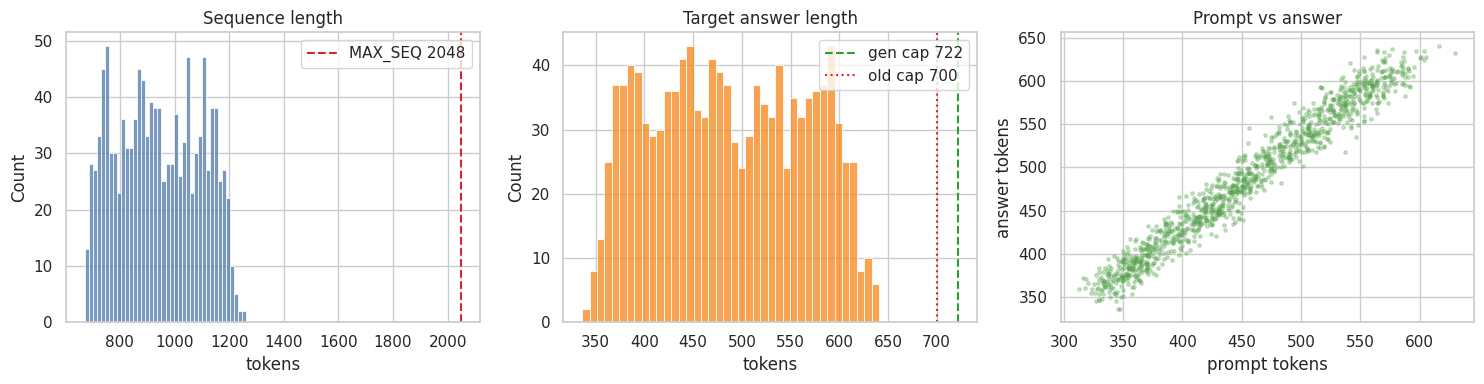

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(aud["total"], bins=40, color="#4C78A8", ax=ax[0])
ax[0].axvline(MAX_SEQ, color="#D62728", ls="--", label=f"MAX_SEQ {MAX_SEQ}"); ax[0].legend()
ax[0].set_title("Sequence length"); ax[0].set_xlabel("tokens")

sns.histplot(aud["answer"], bins=40, color="#F58518", ax=ax[1])
ax[1].axvline(GEN_CAP, color="#2CA02C", ls="--", label=f"gen cap {GEN_CAP}")
ax[1].axvline(700, color="#D62728", ls=":", label="old cap 700"); ax[1].legend()
ax[1].set_title("Target answer length"); ax[1].set_xlabel("tokens")

ax[2].scatter(aud["prompt"], aud["answer"], s=6, alpha=.3, color="#54A24B")
ax[2].set_xlabel("prompt tokens"); ax[2].set_ylabel("answer tokens"); ax[2].set_title("Prompt vs answer")

plt.tight_layout(); plt.savefig(FIG/"fig2_tokens.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig2_tokens.png","figures/fig2_tokens.png")

## 7 · Load model in 4-bit

Gradient checkpointing is **always on**. Disabling it on a large-VRAM card is what pushed the
previous run to 74 GB. Reentrant mode is used because the non-reentrant variant re-runs the
forward pass and conflicts with stochastic LoRA dropout.


In [ ]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

QUANT = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                           bnb_4bit_compute_dtype=DTYPE, bnb_4bit_use_double_quant=True)

def fresh_model():
    m = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=QUANT,
            device_map={"":0}, torch_dtype=DTYPE, attn_implementation="sdpa")
    m.config.use_cache = False
    return m

def attach_lora(m):
    m = prepare_model_for_kbit_training(m, use_gradient_checkpointing=True)
    m.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": True})
    m.enable_input_require_grads()
    return get_peft_model(m, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
                                        task_type="CAUSAL_LM", target_modules="all-linear"))

def free_gpu():
    for n in ("model","trainer","base_model"):
        if n in globals(): del globals()[n]
    gc.collect(); torch.cuda.empty_cache()

free_gpu()
model = guard(lambda: attach_lora(fresh_model()))
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
used      = torch.cuda.memory_allocated()/1024**3
print(f"\ntrainable LoRA : {trainable:,} ({100*trainable/total:.2f}%)")
print(f"GPU used       : {used:.1f} GiB of {GPU_VRAM:.1f}")
pd.DataFrame([{"group":"LoRA (trainable)","params":trainable},
              {"group":"Base 4-bit (frozen)","params":total-trainable}]).to_csv(TAB/"params.csv", index=False)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


trainable LoRA : 29,933,568 (1.73%)
GPU used       : 2.6 GiB of 14.6


## 8 · Train

Prints an estimated duration before starting, and shows a live progress bar with steps
completed, rate, and time remaining. Batch size adapts to available VRAM.


In [ ]:
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback, TrainerCallback

if   GPU_VRAM >= 35: PDB, GA = 4, 4
elif GPU_VRAM >= 20: PDB, GA = 2, 8
else:                PDB, GA = 1, 16
EFF, EPOCHS, EVAL_STEPS, LR = PDB*GA, 2, 15, 1e-4
spe        = math.ceil(len(train_ds)/EFF)
max_steps  = spe*EPOCHS
sec_step   = 4.0 if GPU_VRAM < 20 else 2.2
print(f"batch {PDB} x accum {GA} = {EFF} | {spe} steps/epoch | {max_steps} max steps")
print(f"ESTIMATED TRAINING TIME: {max_steps*sec_step/60:.0f}-{max_steps*sec_step*1.4/60:.0f} min")
print("Early stopping may finish sooner.\n")

args = TrainingArguments(
    output_dir=str(CKPT), overwrite_output_dir=True, num_train_epochs=EPOCHS,
    per_device_train_batch_size=PDB, per_device_eval_batch_size=PDB,
    gradient_accumulation_steps=GA, learning_rate=LR, weight_decay=0.01,
    warmup_ratio=0.10, lr_scheduler_type="cosine", optim="paged_adamw_8bit",
    max_grad_norm=0.3, bf16=BF16, fp16=not BF16,
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": True},
    eval_strategy="steps", eval_steps=EVAL_STEPS, save_strategy="steps", save_steps=EVAL_STEPS,
    logging_steps=5, logging_first_step=True, load_best_model_at_end=True,
    metric_for_best_model="eval_loss", greater_is_better=False, save_total_limit=2,
    report_to="none", remove_unused_columns=False, seed=SEED, data_seed=SEED,
    disable_tqdm=False)

class Progress(TrainerCallback):
    def on_log(self, args, state, control, logs=None, **kw):
        if logs and "loss" in logs and state.global_step % 15 == 0:
            el = time.time()-self._t0
            eta = el/max(state.global_step,1)*(max_steps-state.global_step)
            print(f"  step {state.global_step}/{max_steps} | loss {logs['loss']:.4f} | ETA {eta/60:.1f} min")
    def on_train_begin(self, *a, **kw): self._t0 = time.time()

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=collate,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=3), Progress()])

t0 = time.time()
guard(trainer.train)
wall = time.time()-t0

log = pd.DataFrame(trainer.state.log_history)
ACTUAL_EPOCHS = float(log["epoch"].max())
BEST_CKPT, BEST_LOSS = trainer.state.best_model_checkpoint, trainer.state.best_metric
STEPS = int(trainer.state.global_step)
print(f"\nDONE in {wall/60:.1f} min | epochs {ACTUAL_EPOCHS:.2f} of {EPOCHS} requested"
      f" | steps {STEPS} | best eval loss {BEST_LOSS:.4f}")
log.to_csv(TAB/"training_log.csv", index=False); mirror(TAB/"training_log.csv","tables/training_log.csv")

No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


batch 1 x accum 16 = 16 | 75 steps/epoch | 150 max steps
ESTIMATED TRAINING TIME: 10-14 min
Early stopping may finish sooner.



Step,Training Loss,Validation Loss
15,0.516800,0.414950
30,0.199600,0.186778
45,0.124900,0.163987


  step 15/150 | loss 0.5168 | ETA 343.3 min
  step 30/150 | loss 0.1996 | ETA 337.0 min
  step 45/150 | loss 0.1249 | ETA 302.8 min


Step,Training Loss,Validation Loss
15,0.516800,0.414950
30,0.199600,0.186778
45,0.124900,0.163987
60,0.082700,0.161268
75,0.073500,0.167186
90,0.062800,0.162627
105,0.060700,0.167731


  step 60/150 | loss 0.0827 | ETA 263.7 min
  step 75/150 | loss 0.0735 | ETA 221.6 min
  step 90/150 | loss 0.0628 | ETA 178.5 min
  step 105/150 | loss 0.0607 | ETA 134.5 min

DONE in 321.7 min | epochs 1.40 of 2 requested | steps 105 | best eval loss 0.1613


### Figure 3 — training curves


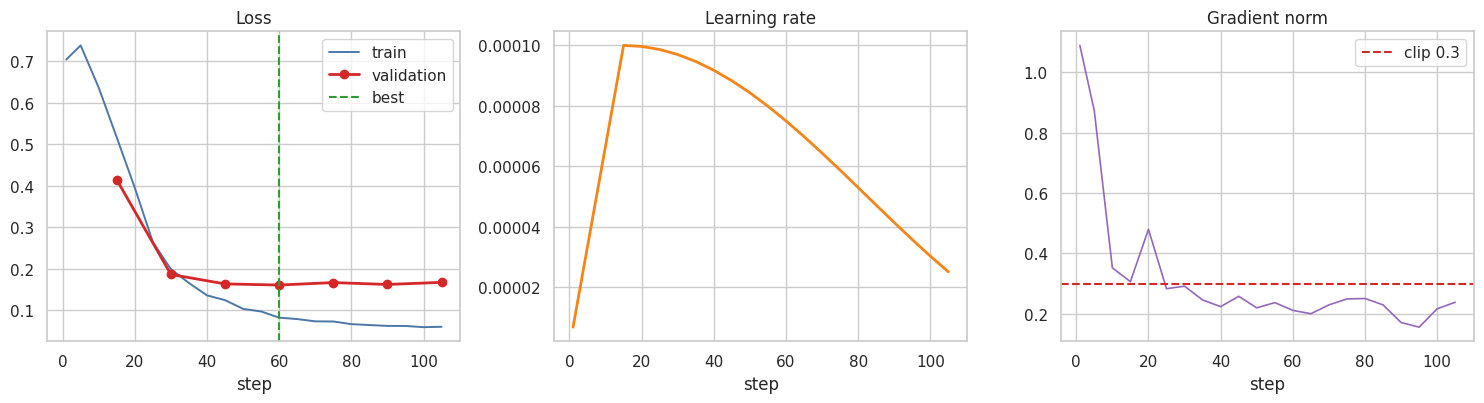

In [ ]:
tr = log.dropna(subset=["loss"]); ev = log.dropna(subset=["eval_loss"])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(tr["step"], tr["loss"], color="#4C78A8", lw=1.4, label="train")
ax[0].plot(ev["step"], ev["eval_loss"], "o-", color="#D62728", lw=2, ms=6, label="validation")
if BEST_CKPT:
    ax[0].axvline(int(str(BEST_CKPT).rsplit("-",1)[-1]), color="#2CA02C", ls="--", label="best")
ax[0].legend(); ax[0].set_title("Loss"); ax[0].set_xlabel("step")

ax[1].plot(tr["step"], tr["learning_rate"], color="#F58518", lw=2)
ax[1].set_title("Learning rate"); ax[1].set_xlabel("step")

ax[2].plot(tr["step"], tr["grad_norm"], color="#9467BD", lw=1.2)
ax[2].axhline(0.3, color="#D62728", ls="--", label="clip 0.3"); ax[2].legend()
ax[2].set_title("Gradient norm"); ax[2].set_xlabel("step")

plt.tight_layout(); plt.savefig(FIG/"fig3_training.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig3_training.png","figures/fig3_training.png")
if len(ev) >= 2 and ev["eval_loss"].is_monotonic_increasing:
    print("\nNOTE: validation loss rose at every evaluation — the model fits this target almost")
    print("immediately. Worth reporting as a property of the rule-derived target.")

## 9 · Save the adapter

Saved and mirrored to Drive **before** evaluation, so a later failure cannot cost you the
trained model.


In [ ]:
ADAPTER = RUN/"adapter"
model.save_pretrained(ADAPTER); tok.save_pretrained(ADAPTER)
shutil.make_archive("/content/mcasm_adapter", "zip", ADAPTER)
mirror(ADAPTER, "adapter"); mirror("/content/mcasm_adapter.zip", "mcasm_adapter.zip")
print(f"adapter saved: {sum(f.stat().st_size for f in ADAPTER.rglob('*') if f.is_file())/1024**2:.0f} MB")
print("mirrored to Drive — safe from session loss")

adapter saved: 129 MB
mirrored to Drive — safe from session loss


## 10 · Evaluation functions

`run_eval` generates in **batches** rather than one at a time — the previous run's single-item
loop was the main cause of its slowness. Progress bars report items completed and time
remaining.


In [ ]:
from scipy.stats import kendalltau, spearmanr

def parse_output(text, ids):
    if not text: return None
    s = text.strip()
    if "```" in s:
        p = [x for x in s.split("```") if "{" in x]
        if p: s = p[0].replace("json","",1).strip()
    a, b = s.find("{"), s.rfind("}")
    if a == -1 or b <= a: return None
    try: o = json.loads(s[a:b+1])
    except json.JSONDecodeError: return None
    if not isinstance(o, dict) or "ranking" not in o: return None
    valid, seen, rk = set(ids), set(), []
    for f in o["ranking"]:
        if isinstance(f,str) and f in valid and f not in seen: rk.append(f); seen.add(f)
    o["ranking"] = rk + [f for f in ids if f not in seen]
    o["_complete"] = len(rk) == len(ids)
    return o

def ranks_of(order, ids):
    pos = {f:i for i,f in enumerate(order)}
    return np.array([pos.get(f, len(order)) for f in ids], float)

def score(pred, gold):
    ids = list(gold); p, g = ranks_of(pred,ids), ranks_of(gold,ids)
    t,_ = kendalltau(p,g,variant="b"); r,_ = spearmanr(p,g)
    out = {"tau_b": 0. if np.isnan(t) else float(t), "spearman": 0. if np.isnan(r) else float(r)}
    rel = {f: len(gold)-i for i,f in enumerate(gold)}
    for k in (3,5):
        if len(ids) >= k:
            out[f"p@{k}"] = len(set(pred[:k]) & set(gold[:k]))/k
            dcg  = sum(rel.get(f,0)/np.log2(i+2) for i,f in enumerate(pred[:k]))
            idcg = sum(v/np.log2(i+2) for i,v in enumerate(sorted(rel.values(),reverse=True)[:k]))
            out[f"ndcg@{k}"] = dcg/idcg if idcg else 0.
    return out

IND = [("internet","public"),("public","public"),("exposed","public"),
       ("unauthenticated","noauth"),("no authentication","noauth"),
       ("unencrypted","unencrypted"),("not encrypted","unencrypted"),
       ("hardcoded","secret_in_code"),("credential","secret_in_code"),("secret","secret_in_code"),
       ("cross-account","cross_account"),("wildcard","wildcard"),("admin","priv=admin"),
       ("privilege escalation","privesc"),("privesc","privesc"),("shared","shared_infra")]

def grounding(why, line):
    t, s = str(why).lower(), line.lower(); c = sup = 0
    for ph, ind in IND:
        if ph in t: c += 1; sup += int(ind in s)
    for p in re.findall(r"port\D{0,3}(\d{2,5})", t): c += 1; sup += int(p in s)
    return sup/c if c else 1.0

def bootstrap_ci(v, clusters=None, n_boot=4000):
    v = np.asarray(v, float)
    if not len(v): return {"point":np.nan,"lo":np.nan,"hi":np.nan,"n_units":0}
    rng = np.random.default_rng(SEED); pt = float(v.mean())
    if clusters is None:
        d = [v[rng.integers(0,len(v),len(v))].mean() for _ in range(n_boot)]; nu = len(v)
    else:
        ix = collections.defaultdict(list)
        for i,c in enumerate(clusters): ix[c].append(i)
        ks = list(ix); nu = len(ks)
        d = [v[[i for j in rng.integers(0,len(ks),len(ks)) for i in ix[ks[j]]]].mean()
             for _ in range(n_boot)]
    lo,hi = np.percentile(d,[2.5,97.5])
    return {"point":pt,"lo":float(lo),"hi":float(hi),"n_units":nu}

def perm_test(a, b, n=10000):
    a,b = np.asarray(a,float), np.asarray(b,float); m = min(len(a),len(b))
    d = a[:m]-b[:m]; obs = float(d.mean()); rng = np.random.default_rng(SEED)
    null = (rng.choice([-1.,1.],(n,len(d)))*d).mean(axis=1)
    return {"mean_difference":obs, "p_value":float((np.abs(null)>=abs(obs)).mean()), "n_pairs":m}
print("evaluation functions ready")

evaluation functions ready


In [ ]:
GEN_BATCH = 8 if GPU_VRAM >= 20 else 4

@torch.no_grad()
def generate_batch(mdl, msg_list, max_new):
    prompts = [tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
               for m in msg_list]
    tok.padding_side = "left"
    enc = tok(prompts, return_tensors="pt", padding=True).to(mdl.device)
    out = mdl.generate(**enc, max_new_tokens=max_new, do_sample=False,
                       pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id)
    tok.padding_side = "right"
    n = enc["input_ids"].shape[1]
    return [tok.decode(o[n:], skip_special_tokens=True) for o in out]

def shuffled(rec, seed):
    lines = rec["messages"][1]["content"].split("\n")
    head = [l for l in lines if "::" not in l]; body = [l for l in lines if "::" in l]
    np.random.default_rng(seed).shuffle(body)
    return [dict(rec["messages"][0]), {"role":"user","content":"\n".join(head+body)}]

def run_eval(mdl, records, arm, n_shuffles=1):
    jobs = [(r, s) for r in records for s in range(n_shuffles)]
    rows, orders = [], collections.defaultdict(list)
    bar = tqdm(total=len(jobs), desc=f"{arm}", unit="gen")
    t0 = time.time()
    for i in range(0, len(jobs), GEN_BATCH):
        chunk = jobs[i:i+GEN_BATCH]
        msgs = [r["messages"][:2] if s==0 else shuffled(r, SEED+s) for r,s in chunk]
        texts = generate_batch(mdl, msgs, GEN_CAP)
        for (rec,s), txt in zip(chunk, texts):
            ids, gold = rec["input_order"], rec["target"]["ranking"]
            src = {l.split(" :: ")[0].strip(): l for l in rec["messages"][1]["content"].split("\n") if "::" in l}
            o = parse_output(txt, ids)
            if o is None:
                rows.append({"arm":arm,"instance_id":rec["instance_id"],"shuffle":s,"valid":0,
                             "tau_b":0.,"spearman":0.,"ssvc_acc":np.nan,"grounding":np.nan,"raw":txt[:300]})
                continue
            orders[rec["instance_id"]].append(o["ranking"])
            gt, pr = rec["target"].get("ssvc",{}), o.get("ssvc",{}) or {}
            acc = np.mean([pr.get(k)==v for k,v in gt.items()]) if gt else np.nan
            gv = [grounding(w, src.get(k,"")) for k,w in (o.get("why",{}) or {}).items() if k in src]
            rows.append({"arm":arm,"instance_id":rec["instance_id"],"shuffle":s,"valid":1,
                         **score(o["ranking"], gold),
                         "ssvc_acc":float(acc) if acc==acc else np.nan,
                         "grounding":float(np.mean(gv)) if gv else np.nan,
                         "raw":json.dumps(o)[:300]})
        done = min(i+GEN_BATCH, len(jobs)); el = time.time()-t0
        bar.update(len(chunk))
        bar.set_postfix_str(f"{el/done:.1f}s/gen | ETA {(len(jobs)-done)*el/done/60:.1f}m")
    bar.close()
    df = pd.DataFrame(rows)
    if n_shuffles > 1:
        st = {}
        for iid, os_ in orders.items():
            if len(os_) < 2: continue
            base = os_[0]
            pw = [kendalltau(ranks_of(os_[a],base), ranks_of(os_[b],base), variant="b")[0]
                  for a in range(len(os_)) for b in range(a+1,len(os_))]
            pw = [x for x in pw if not np.isnan(x)]
            if pw: st[iid] = float(np.mean(pw))
        df["stability"] = df["instance_id"].map(st)
    return df
print(f"batched generation ready | batch {GEN_BATCH} | cap {GEN_CAP} tokens")

batched generation ready | batch 4 | cap 722 tokens


## 11 · Evaluation plan

Three arms are compared. A single number proves nothing — the comparison is the result.

| Arm | Description |
|---|---|
| A0 | Base model, no training |
| A1 | Base model with one worked example in the prompt |
| A3 | Fine-tuned model |

`EVAL_N = 60` covers the statistics adequately: confidence intervals cluster on unique
resources, not instances, so sampling more instances adds little precision. Raise it only if
you have spare compute.


In [ ]:
EVAL_N, N_SHUFFLES = 60, 2

eval_recs = splits["validation"][:EVAL_N]
n_gen = EVAL_N*N_SHUFFLES + EVAL_N*2
sec = 1.4 if GPU_VRAM >= 20 else 2.6
print(f"instances     : {EVAL_N}")
print(f"generations   : A3 {EVAL_N*N_SHUFFLES} + A0 {EVAL_N} + A1 {EVAL_N} = {n_gen}")
print(f"ESTIMATED TIME: {n_gen*sec/60:.0f}-{n_gen*sec*1.5/60:.0f} min for all three arms")

instances     : 60
generations   : A3 120 + A0 60 + A1 60 = 240
ESTIMATED TIME: 10-16 min for all three arms


### Arm A3 — fine-tuned


In [ ]:
model.eval(); model.config.use_cache = True
df_a3 = guard(run_eval, model, eval_recs, "A3_finetuned", N_SHUFFLES)
print(f"\ntau {df_a3['tau_b'].mean():.3f} | valid JSON {df_a3['valid'].mean():.1%}"
      f" | stability {df_a3['stability'].mean():.3f}")
df_a3.to_csv(TAB/"eval_a3.csv", index=False); mirror(TAB/"eval_a3.csv","tables/eval_a3.csv")
if df_a3["valid"].mean() < 0.9:
    print("\nWARNING: low JSON validity. Inspect the `raw` column before trusting tau.")

A3_finetuned:   0%|          | 0/120 [00:00<?, ?gen/s]

/usr/local/lib/python3.12/dist-packages/transformers/generation/configuration_utils.py:629: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/transformers/generation/configuration_utils.py:634: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/transformers/generation/configuration_utils.py:651: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(



tau 0.632 | valid JSON 98.3% | stability 0.676


### Arms A0 and A1 — untrained baselines


In [23]:
free_gpu()
base_model = guard(fresh_model); base_model.eval(); base_model.config.use_cache = True

df_a0 = guard(run_eval, base_model, eval_recs, "A0_zeroshot", 1)
print(f"A0: tau {df_a0['tau_b'].mean():.3f} | valid {df_a0['valid'].mean():.1%}")

demo = splits["train"][0]
shot = (f"Example input:\n{demo['messages'][1]['content'][:700]}\n\n"
        f"Example output:\n{demo['messages'][2]['content'][:500]}\n\n---\n\n")
oneshot = []
for r in eval_recs:
    r2 = json.loads(json.dumps(r)); r2["messages"][1]["content"] = shot + r2["messages"][1]["content"]
    oneshot.append(r2)

df_a1 = guard(run_eval, base_model, oneshot, "A1_oneshot", 1)
print(f"A1: tau {df_a1['tau_b'].mean():.3f} | valid {df_a1['valid'].mean():.1%}")

del base_model; gc.collect(); torch.cuda.empty_cache()

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

A0_zeroshot:   0%|          | 0/60 [00:00<?, ?gen/s]

/usr/local/lib/python3.12/dist-packages/transformers/generation/configuration_utils.py:629: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/transformers/generation/configuration_utils.py:634: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/transformers/generation/configuration_utils.py:651: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


A0: tau 0.065 | valid 73.3%


A1_oneshot:   0%|          | 0/60 [00:00<?, ?gen/s]

A1: tau 0.288 | valid 95.0%


## 12 · Results


In [24]:
allr = pd.concat([df_a0, df_a1, df_a3], ignore_index=True)
allr.to_csv(TAB/"eval_all.csv", index=False); mirror(TAB/"eval_all.csv","tables/eval_all.csv")

summ = []
for arm, g in allr.groupby("arm"):
    f = g[g["shuffle"]==0]
    ci = bootstrap_ci(f["tau_b"].values, f["instance_id"].values)
    summ.append({"arm":arm, "tau_b":ci["point"], "ci_lo":ci["lo"], "ci_hi":ci["hi"],
                 "spearman":f["spearman"].mean(),
                 "ndcg@5":f.get("ndcg@5",pd.Series(dtype=float)).mean(),
                 "p@3":f.get("p@3",pd.Series(dtype=float)).mean(),
                 "json_validity":f["valid"].mean(), "ssvc_acc":f["ssvc_acc"].mean(),
                 "grounding":f["grounding"].mean(),
                 "stability":g["stability"].mean() if "stability" in g else np.nan,
                 "n":len(f)})
summary = pd.DataFrame(summ).sort_values("tau_b", ascending=False)
display(summary.round(4))
summary.to_csv(TAB/"summary.csv", index=False); mirror(TAB/"summary.csv","tables/summary.csv")

a3 = df_a3[df_a3["shuffle"]==0].sort_values("instance_id")["tau_b"].values
a0 = df_a0.sort_values("instance_id")["tau_b"].values
a1 = df_a1.sort_values("instance_id")["tau_b"].values
tests = pd.DataFrame([{"comparison":"A3 vs A0", **perm_test(a3,a0)},
                      {"comparison":"A3 vs A1", **perm_test(a3,a1)},
                      {"comparison":"A1 vs A0", **perm_test(a1,a0)}])
tests["significant"] = tests["p_value"] < 0.05
display(tests.round(4))
tests.to_csv(TAB/"significance.csv", index=False); mirror(TAB/"significance.csv","tables/significance.csv")

,arm,tau_b,ci_lo,ci_hi,spearman,ndcg@5,p@3,json_validity,ssvc_acc,grounding,stability,n
2,A3_finetuned,0.6470,0.6023,0.6892,0.7618,0.9446,0.7944,1.0000,0.8064,NaN,0.6756,60
1,A1_oneshot,0.2876,0.2354,0.3406,0.3834,0.8168,0.5322,0.9500,0.2468,NaN,NaN,60
0,A0_zeroshot,0.0655,0.0131,0.1202,0.0802,0.6930,0.3409,0.7333,0.0645,0.7451,NaN,60


,comparison,mean_difference,p_value,n_pairs,significant
0,A3 vs A0,0.5816,0.0,60,True
1,A3 vs A1,0.3594,0.0,60,True
2,A1 vs A0,0.2221,0.0,60,True


### Figure 4 — headline result


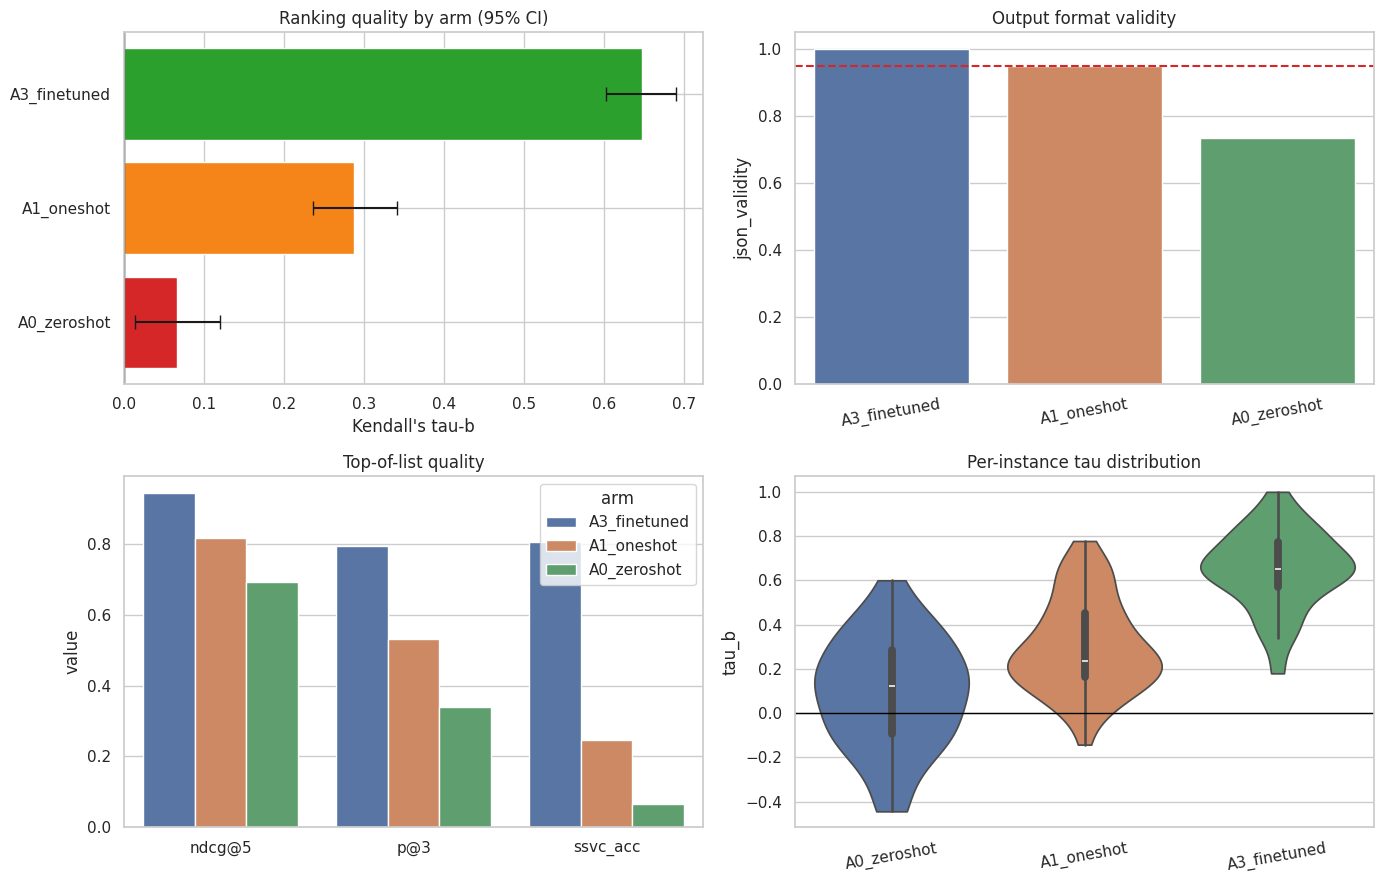

In [25]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
o = summary.sort_values("tau_b")
cols = ["#D62728" if t<0.1 else "#F58518" if t<0.4 else "#2CA02C" for t in o["tau_b"]]
ax[0,0].barh(o["arm"], o["tau_b"], color=cols,
             xerr=[o["tau_b"]-o["ci_lo"], o["ci_hi"]-o["tau_b"]], capsize=5)
ax[0,0].axvline(0, color="black", lw=1); ax[0,0].set_xlabel("Kendall's tau-b")
ax[0,0].set_title("Ranking quality by arm (95% CI)")

sns.barplot(data=summary, x="arm", y="json_validity", hue="arm", legend=False, palette="deep", ax=ax[0,1])
ax[0,1].axhline(0.95, color="#D62728", ls="--"); ax[0,1].set_ylim(0,1.05)
ax[0,1].set_title("Output format validity"); ax[0,1].set_xlabel(""); ax[0,1].tick_params(axis="x", rotation=10)

mm = summary.melt(id_vars="arm", value_vars=[c for c in ["ndcg@5","p@3","ssvc_acc"] if c in summary],
                  var_name="metric", value_name="value")
sns.barplot(data=mm, x="metric", y="value", hue="arm", palette="deep", ax=ax[1,0])
ax[1,0].set_title("Top-of-list quality"); ax[1,0].set_xlabel("")

fa = allr[(allr["shuffle"]==0)&(allr["valid"]==1)]
sns.violinplot(data=fa, x="arm", y="tau_b", hue="arm", legend=False, palette="deep", cut=0, ax=ax[1,1])
ax[1,1].axhline(0, color="black", lw=1); ax[1,1].set_title("Per-instance tau distribution")
ax[1,1].set_xlabel(""); ax[1,1].tick_params(axis="x", rotation=10)

plt.tight_layout(); plt.savefig(FIG/"fig4_results.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig4_results.png","figures/fig4_results.png")

### Figure 5 — robustness and explanation quality

**Stability** is agreement across shuffled input orders. Below 0.8 means the model is partly
ranking by position rather than risk. **Grounding** is the share of claims in its explanations
supported by the input; `1 − grounding` is the hallucination rate.


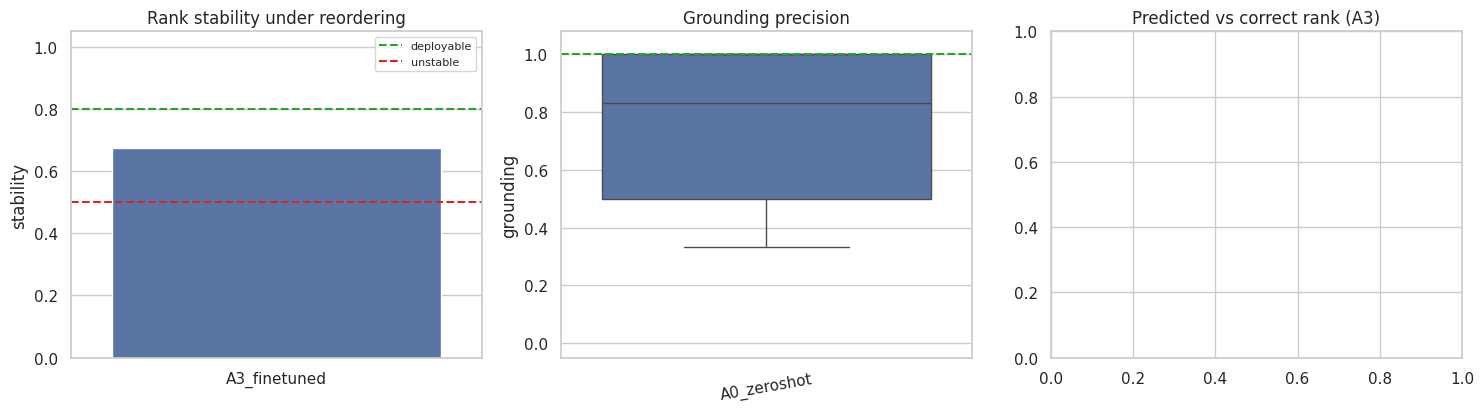

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
st = allr.dropna(subset=["stability"]).groupby("arm")["stability"].mean().reset_index() \
     if "stability" in allr else pd.DataFrame(columns=["arm","stability"])
if len(st):
    sns.barplot(data=st, x="arm", y="stability", hue="arm", legend=False, palette="deep", ax=ax[0])
    ax[0].axhline(0.8, color="#2CA02C", ls="--", label="deployable")
    ax[0].axhline(0.5, color="#D62728", ls="--", label="unstable")
    ax[0].legend(fontsize=8); ax[0].set_ylim(0,1.05)
ax[0].set_title("Rank stability under reordering"); ax[0].set_xlabel("")

gr = allr.dropna(subset=["grounding"])
if len(gr):
    sns.boxplot(data=gr, x="arm", y="grounding", hue="arm", legend=False, palette="deep", ax=ax[1])
    ax[1].axhline(1.0, color="#2CA02C", ls="--")
ax[1].set_ylim(-.05,1.08); ax[1].set_title("Grounding precision"); ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=10)

pairs=[]
for _,row in df_a3[(df_a3["shuffle"]==0)&(df_a3["valid"]==1)].iterrows():
    rec = next(r for r in eval_recs if r["instance_id"]==row["instance_id"])
    try: pred = json.loads(row["raw"])["ranking"]
    except Exception: continue
    gold = rec["target"]["ranking"]
    for gi,f in enumerate(gold):
        if f in pred: pairs.append({"gold":gi+1,"pred":pred.index(f)+1})
pairs = pd.DataFrame(pairs)
if len(pairs):
    ax[2].scatter(pairs["gold"], pairs["pred"], s=14, alpha=.35, color="#4C78A8")
    lim = max(pairs["gold"].max(), pairs["pred"].max())
    ax[2].plot([1,lim],[1,lim],"k--",lw=1)
    ax[2].set_xlabel("gold rank"); ax[2].set_ylabel("predicted rank")
ax[2].set_title("Predicted vs correct rank (A3)")

plt.tight_layout(); plt.savefig(FIG/"fig5_robustness.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig5_robustness.png","figures/fig5_robustness.png")
if len(pairs): pairs.to_csv(TAB/"rank_errors.csv", index=False)

### Figure 6 — worked example for the appendix


In [28]:
ok = df_a3[(df_a3["shuffle"]==0) & (df_a3["valid"]==1)]
if not len(ok):
    print("no valid A3 output to display")
else:
    ex  = ok.sort_values("tau_b", ascending=False).iloc[0]
    rec = next(r for r in eval_recs if r["instance_id"] == ex["instance_id"])
    gold = rec["target"]["ranking"]
    src  = {l.split(" :: ")[0].strip(): l.split(" :: ")[1]
            for l in rec["messages"][1]["content"].split("\n") if "::" in l}

    # The stored `raw` column was truncated to 300 chars, so it may not parse.
    # Salvage what we can; fall back to regenerating this single instance.
    pred = None
    try:
        pred = json.loads(ex["raw"])
    except json.JSONDecodeError:
        ids = re.findall(r'"(res-[0-9a-f]{12})"', str(ex["raw"]))
        seen, order = set(), []
        for i in ids:
            if i not in seen: order.append(i); seen.add(i)
        if len(order) >= len(gold) * 0.6:
            pred = {"ranking": order + [g for g in gold if g not in seen], "ssvc": {}, "why": {}}
            print("(reconstructed from truncated record — explanations unavailable)\n")

    if pred is None:
        print("regenerating this instance to show full output...\n")
        txt  = generate_batch(model, [rec["messages"][:2]], GEN_CAP)[0]
        pred = parse_output(txt, rec["input_order"])

    if pred is None:
        print("could not recover a parseable example")
    else:
        print(f"instance {ex['instance_id']} | tau {ex['tau_b']:.3f}\n")
        print(f"{'#':>2}  {'FINDING':<46} {'SSVC':<8} CORRECT#")
        print("-" * 76)
        for i, f in enumerate(pred["ranking"][:10], 1):
            print(f"{i:>2}  {src.get(f,'')[:44]:<46} "
                  f"{(pred.get('ssvc') or {}).get(f,'?'):<8} "
                  f"{gold.index(f)+1 if f in gold else '-'}")
        why = pred.get("why") or {}
        if why:
            print("\nMODEL EXPLANATIONS:")
            for f, w in list(why.items())[:3]:
                print(f"  [grounding {grounding(w, src.get(f,'')):.2f}] {str(w)[:140]}")

(reconstructed from truncated record — explanations unavailable)

instance validation_00014 | tau 1.000

 #  FINDING                                        SSVC     CORRECT#
----------------------------------------------------------------------------
 1                                                 ?        1
 2                                                 ?        2
 3                                                 ?        3
 4                                                 ?        4
 5                                                 ?        5
 6                                                 ?        6
 7                                                 ?        7
 8                                                 ?        8
 9                                                 ?        9


## 13 · Save everything


In [29]:
manifest = {
  "created_utc": datetime.now(timezone.utc).isoformat(),
  "input_sha256": INPUT_SHA,
  "model": MODEL_ID,
  "gpu": GPU_NAME, "vram_gib": round(GPU_VRAM,1),
  "training": {"epochs_requested": EPOCHS, "epochs_actual": ACTUAL_EPOCHS,
               "global_steps": STEPS, "learning_rate": LR, "effective_batch": EFF,
               "best_eval_loss": BEST_LOSS, "wall_minutes": round(wall/60,1),
               "lora_r": 16, "lora_alpha": 32, "trainable_params": int(trainable),
               "max_seq_length": MAX_SEQ, "gradient_checkpointing": True},
  "evaluation": {"eval_instances": EVAL_N, "n_shuffles": N_SHUFFLES,
                 "generation_cap_tokens": GEN_CAP, "generation_batch": GEN_BATCH,
                 "split": "validation"},
  "data_integrity": integrity.to_dict("records"),
  "cross_split_overlap": overlap,
  "results": summary.to_dict("records"),
  "significance": tests.to_dict("records"),
  "limitations": [
    "Gold rankings are rule-derived, not expert judgement. Results show the model can learn the ranking function, not that the ranking is correct.",
    "Notebook 03 used test instances for model selection, so evaluation here uses the validation split.",
    "Single training seed; variance across seeds is not measured.",
    "Arms A2 and A4 (two-stage training) are future work.",
  ],
  "next": ["Corpus C: expert annotation by 2-3 raters",
           "Notebook 05: frozen test-set evaluation",
           "Notebook 06: expert comparison — the confirmatory answer to RQ2"],
}
(RUN/"manifest_04.json").write_text(json.dumps(manifest, indent=2, default=str))

assets = RUN/"report_assets"; assets.mkdir(exist_ok=True)
shutil.copytree(FIG, assets/"figures", dirs_exist_ok=True)
shutil.copytree(TAB, assets/"tables", dirs_exist_ok=True)
shutil.copy(RUN/"manifest_04.json", assets/"manifest_04.json")
shutil.make_archive("/content/mcasm_report_assets", "zip", assets)
mirror(assets, "report_assets"); mirror(RUN/"manifest_04.json", "manifest_04.json")
mirror("/content/mcasm_report_assets.zip", "mcasm_report_assets.zip")

print("FIGURES:"); [print("  ", p.name) for p in sorted(FIG.glob("*.png"))]
print("TABLES :"); [print("  ", p.name) for p in sorted(TAB.glob("*.csv"))]
if DRIVE: print(f"\nAll files mirrored to {DRIVE}")

FIGURES:
   fig1_corpus.png
   fig2_tokens.png
   fig3_training.png
   fig4_results.png
   fig5_robustness.png
TABLES :
   eval_a3.csv
   eval_all.csv
   integrity.csv
   params.csv
   significance.csv
   summary.csv
   tokens.csv
   training_log.csv

All files mirrored to /content/drive/MyDrive/mcasm_stage4


In [30]:
from google.colab import files
for f in ["/content/mcasm_adapter.zip", "/content/mcasm_report_assets.zip"]:
    try: files.download(f)
    except Exception: print(f"download failed for {f} — retrieve from Drive")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>